

**Membres du binôme :** Miloud Meziane
**Date :** 11/12/2025



## 0. Configuration de l'environnement

Pour réaliser ce TP, nous utilisons l'écosystème Python scientifique standard.
Nous importons ici l'ensemble des librairies nécessaires :
* **Pandas et Numpy** : Pour la manipulation de données (DataFrames, matrices).
* **Matplotlib** : Pour la visualisation graphique (courbes ROC, histogrammes).
* **Scikit-Learn** : Pour l'ensemble des algorithmes d'apprentissage (Classification, Preprocessing, Validation).

Nous configurons également l'environnement pour améliorer la lisibilité des sorties (suppression de la notation scientifique et des avertissements non critiques).

In [11]:
# 0. IMPORTS ET CONFIGURATION GÉNÉRALE

# 1. Librairies standards 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import pickle  # Pour sauvegarder le pipeline plus tard

# 2. Scikit-Learn : Modèles d'apprentissage
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier

# 3. Scikit-Learn : Préparation des données (Preprocessing)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 4. Scikit-Learn : Évaluation et Sélection
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score, roc_curve, make_scorer
)

# CONFIGURATION

warnings.filterwarnings('ignore')
np.set_printoptions(threshold=10000, suppress=True)

print("Environnement configuré et librairies chargées.")


Environnement configuré et librairies chargées.


## I. Apprentissage supervisé : Feature engineering et Classification

### 1. Chargement des données et préparation

**Objectif :** Importer le jeu de données `credit_scoring.csv`, le convertir en tableau Numpy, analyser la répartition des classes et diviser les données en deux parties égales (50% apprentissage, 50% test).

**Méthodologie :**
* Utilisation de la librairie **Pandas** pour la lecture du fichier (séparateur `;`).
* Transformation du DataFrame en **Numpy Array** (`.values`) pour être compatible avec Scikit-Learn.
* Séparation des variables descriptives (**X**) et de la cible à prédire (**y**).
* Calcul du pourcentage d'exemples positifs et négatifs.
* Division de l'échantillon avec `train_test_split` (`test_size=0.5` et `random_state=1` pour la reproductibilité).

In [12]:
def load_and_split_data(filename, sep=';'):
    """
    Charge, analyse et sépare les données (avec Stratify pour la stabilité).
    """
    # 1. Chargement
    try:
        df = pd.read_csv(filename, sep=sep)
    except:
        df = pd.read_csv(filename, sep=',')

    data = df.values
    X = data[:, :-1].astype(float)
    y = data[:, -1].astype(float)
    
    # 2. Analyse
    n_pos = np.sum(y == 1)
    n_neg = np.sum(y == 0)
    print(f"Dataset : {df.shape}")
    print(f"Répartition : {n_pos} Positifs ({n_pos/len(y):.2%}) / {n_neg} Négatifs")
    
    # 3. Split (Avec Stratify = Meilleure pratique)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.5, random_state=1, stratify=y
    )
    
    return X_train, X_test, y_train, y_test

# Exécution
X_train, X_test, y_train, y_test = load_and_split_data("credit_scoring.csv")


Dataset : (4375, 14)
Répartition : 3159 Positifs (72.21%) / 1216 Négatifs


=== RÉSULTATS DONNÉES BRUTES ===

--- CART ---
Matrice :
[[ 297  311]
 [ 319 1261]]
Accuracy : 0.712 | Précision : 0.802 | Rappel : 0.798
AUC : 0.643
👉 Score Final : 0.757

--- KNN ---
Matrice :
[[ 180  428]
 [ 221 1359]]
Accuracy : 0.703 | Précision : 0.760 | Rappel : 0.860
AUC : 0.648
👉 Score Final : 0.732

--- MLP ---
Matrice :
[[  59  549]
 [  55 1525]]
Accuracy : 0.724 | Précision : 0.735 | Rappel : 0.965
AUC : 0.679
👉 Score Final : 0.730


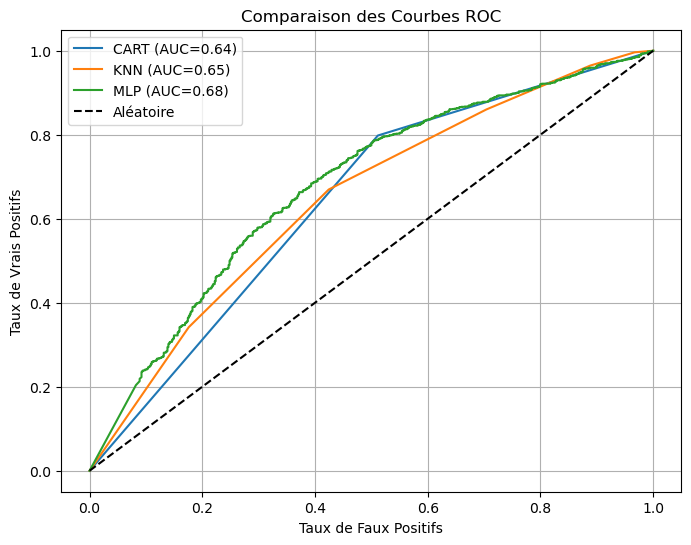


🏆 Le meilleur modèle est : CART avec un score de 0.757


In [13]:
# ============================================================
# QUESTION 2 : APPRENTISSAGE ET ÉVALUATION
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, roc_curve, roc_auc_score
)

# 1. Dictionnaire contenant les algorithmes supervisés (Paramètres imposés)
clfs = {
    'CART': DecisionTreeClassifier(random_state=1),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1)
}

# 2. Fonction d'évaluation
def evaluation(model, X_test, y_test, model_name):
    """
    Affiche la matrice de confusion, calcule les scores et trace la courbe ROC.
    Retourne le score final (Accuracy + Meilleur(Prec, Rec)) / 2.
    """
    # Prédictions
    y_pred = model.predict(X_test)
    
    # Probabilités (nécessaire pour l'AUC et la courbe ROC)
    try:
        y_proba = model.predict_proba(X_test)[:, 1]
    except:
        y_proba = y_pred
        
    # a. Matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    
    # b. Calcul des métriques
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)
    
    # c. Score Final "Métier" : (Accuracy + Meilleur(Précision, Rappel)) / 2
    # On choisit la Précision ici comme critère (éviter de donner un crédit à tort)
    # Tu peux changer 'prec' par 'rec' si tu préfères favoriser le Rappel
    best_criteria = prec 
    score_final = (acc + best_criteria) / 2
    
    # Affichage Texte
    print(f"\n--- {model_name} ---")
    print(f"Matrice :\n{cm}")
    print(f"Accuracy : {acc:.3f} | Précision : {prec:.3f} | Rappel : {rec:.3f}")
    print(f"AUC : {auc:.3f}")
    print(f"👉 Score Final : {score_final:.3f}")
    
    # d. Ajout de la courbe ROC au graphique en cours
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC={auc:.2f})")
    
    return score_final

# 3. Fonction d'apprentissage et de test (Orchestration)
def run_classifiers_train_test(classifiers, X_train, y_train, X_test, y_test):
    """
    Entraîne chaque modèle, affiche les résultats et retourne le meilleur.
    """
    results = {}
    best_score = 0
    best_model_obj = None
    best_model_name = ""
    
    # Initialisation de la figure pour les courbes ROC
    plt.figure(figsize=(8, 6))
    
    # Boucle sur chaque modèle du dictionnaire
    for name, model in classifiers.items():
        # Entraînement
        model.fit(X_train, y_train)
        
        # Évaluation (Appelle la fonction ci-dessus)
        score = evaluation(model, X_test, y_test, name)
        results[name] = score
        
        # Comparaison pour trouver le meilleur
        if score > best_score:
            best_score = score
            best_model_obj = model
            best_model_name = name
            
    # Finalisation de l'affichage du graphique ROC
    plt.plot([0, 1], [0, 1], 'k--', label='Aléatoire')  # Diagonale
    plt.title("Comparaison des Courbes ROC")
    plt.xlabel("Taux de Faux Positifs")
    plt.ylabel("Taux de Vrais Positifs")
    plt.legend()
    plt.grid(True)
    plt.show()  # Affiche le graphique pour de bon
    
    print(f"\n🏆 Le meilleur modèle est : {best_model_name} avec un score de {best_score:.3f}")
    
    return best_model_obj, results

# --- EXÉCUTION Q2 ---
print("=== RÉSULTATS DONNÉES BRUTES ===")
best_model, scores = run_classifiers_train_test(clfs, X_train, y_train, X_test, y_test)



COMPARAISON APRÈS NORMALISATION

--- CART ---
Matrice :
[[ 302  306]
 [ 322 1258]]
Accuracy : 0.713 | Précision : 0.804 | Rappel : 0.796
AUC : 0.646
👉 Score Final : 0.759

--- KNN ---
Matrice :
[[ 270  338]
 [ 212 1368]]
Accuracy : 0.749 | Précision : 0.802 | Rappel : 0.866
AUC : 0.744
👉 Score Final : 0.775

--- MLP ---
Matrice :
[[ 353  255]
 [ 221 1359]]
Accuracy : 0.782 | Précision : 0.842 | Rappel : 0.860
AUC : 0.817
👉 Score Final : 0.812


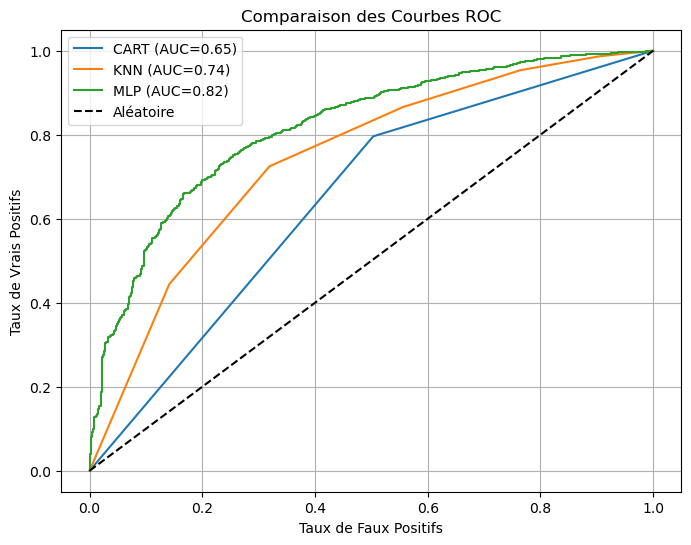


🏆 Le meilleur modèle est : MLP avec un score de 0.812


In [7]:
# ============================================================
# QUESTION 3 : NORMALISATION DES VARIABLES
# ============================================================

from sklearn.preprocessing import StandardScaler

def run_normalization_and_compare(X_train, X_test, y_train, y_test, classifiers):
    """
    Normalise les données (StandardScaler) et relance la comparaison
    des classifieurs définis à la question 2.
    """
    # 1. Initialisation
    scaler = StandardScaler()
    
    # 2. Méthodologie stricte :
    #    - fit sur TRAIN seulement
    #    - transform sur TRAIN et TEST
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    print("\n" + "="*50)
    print("COMPARAISON APRÈS NORMALISATION")
    print("="*50)
    
    # 3. Réutilisation de la fonction de la Q2
    best, scores = run_classifiers_train_test(
        classifiers, X_train_scaled, y_train, X_test_scaled, y_test
    )
    
    return X_train_scaled, X_test_scaled

# --- EXÉCUTION Q3 ---
X_train_scaled, X_test_scaled = run_normalization_and_compare(
    X_train, X_test, y_train, y_test, clfs
)


### 4. Création de nouvelles variables par combinaisons linéaires (ACP)

**Objectif :** Utiliser l'Analyse en Composantes Principales (PCA) pour extraire les 3 axes de variation principaux des données. Nous ajoutons ces 3 nouvelles dimensions aux données normalisées existantes pour enrichir l'information disponible pour les classifieurs.

**Méthodologie :**
1.  Application de `PCA(n_components=3)` sur les données normalisées (`X_train_scaled`).
2.  Transformation des données de test (`X_test_scaled`) selon les mêmes axes.
3.  **Concaténation** des données : `[Données Normalisées] + [3 Variables ACP]`.
4.  Nouvelle évaluation des modèles sur ce jeu de données élargi (16 variables).

In [18]:
 # ============================================================
# QUESTION 4 : ACP AVEC CONCATÉNATION (Stratégie "Hybride")
# ============================================================


# --- 1. SÉCURITÉ : Récupération des noms de colonnes ---
# On recharge juste pour avoir les noms (au cas où df n'existe plus)
try:
    df_temp = pd.read_csv("credit_scoring.csv", sep=';')
except:
    df_temp = pd.read_csv("credit_scoring.csv", sep=',')
    
feature_names = df_temp.columns[:-1] # Toutes les colonnes sauf la target

# --- 2. Fonction d'enrichissement ---
def enrichir_donnees(X_train_sc, X_test_sc):
    """
    Calcule l'ACP et l'ajoute aux données (13 cols -> 16 cols)
    """
    print("--- Calcul ACP et Concaténation ---")
    # 1. Calcul ACP sur les données normalisées
    pca = PCA(n_components=3)
    X_train_pca = pca.fit_transform(X_train_sc)
    X_test_pca = pca.transform(X_test_sc)
    
    # 2. CONCATÉNATION (Stratégie gagnante)
    # On colle les 3 colonnes ACP à droite des 13 colonnes scalées
    X_train_final = np.hstack([X_train_sc, X_train_pca])
    X_test_final = np.hstack([X_test_sc, X_test_pca])
    
    print(f"✅ Dimensions après concaténation : {X_train_final.shape} (16 variables)")
    return X_train_final, X_test_final

# --- EXÉCUTION Q4 ---
# Assure-toi que X_train_scaled existe (issue de la Q3)
X_train_final, X_test_final = enrichir_donnees(X_train_scaled, X_test_scaled)

# On met à jour les noms des colonnes (13 anciens + 3 nouveaux)
nom_cols_final = np.append(feature_names, ["PCA1", "PCA2", "PCA3"])

print("Nouveaux noms de colonnes prêts.")

--- Calcul ACP et Concaténation ---
✅ Dimensions après concaténation : (2187, 16) (16 variables)
Nouveaux noms de colonnes prêts.


### 5. Sélection de variables

**Objectif :** Simplifier le modèle en ne gardant que les variables les plus pertinentes (Feature Selection). Cela permet souvent d'améliorer la performance en éliminant le "bruit".

**Méthodologie :**
1.  **Importance des variables :** Nous utilisons un *Random Forest* pour calculer le poids de chaque variable dans la décision.
2.  **Nombre optimal :** Nous testons itérativement les performances en ajoutant les meilleures variables une par une pour trouver le "coude" (le nombre idéal).
3.  **Explicabilité (SHAP) :** Nous utilisons la librairie SHAP pour visualiser l'impact de chaque variable (positif ou négatif) sur l'octroi du crédit.


--- 1. Importance (RF) ---
Top 5 variables : ['Income' 'PCA2' 'Seniority' 'PCA3' 'Price']


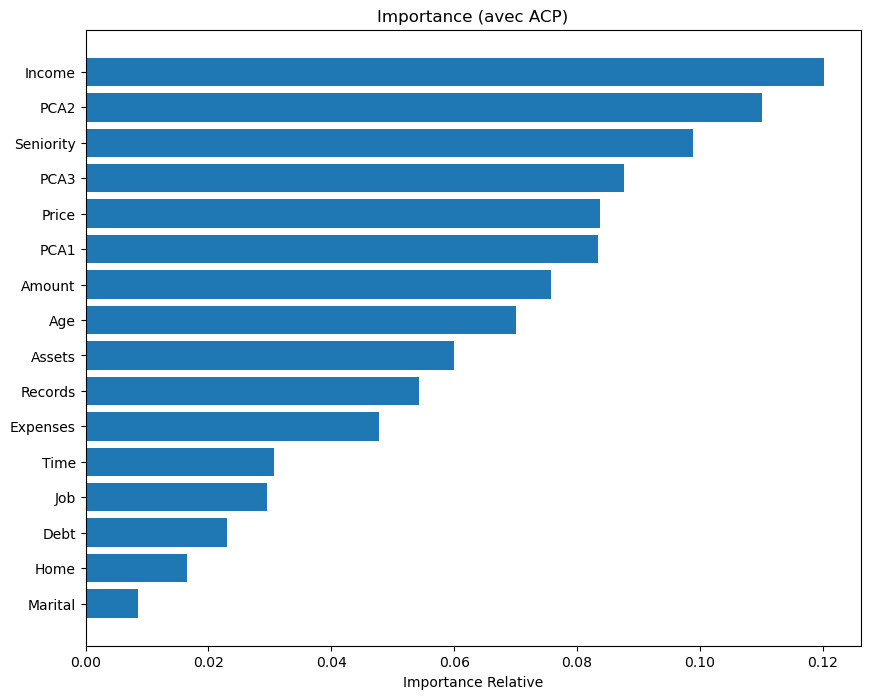


--- 2. Sélection Optimale (MLP) ---


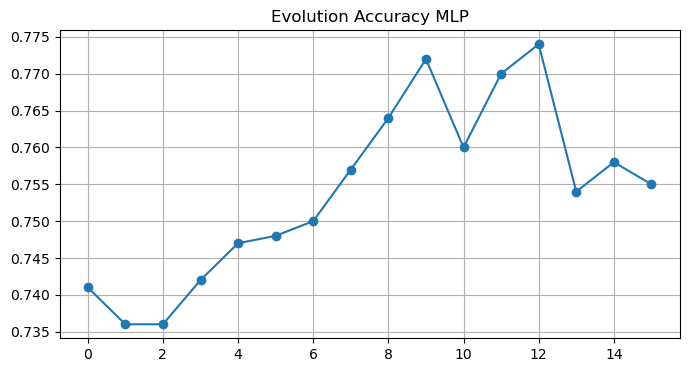

👉 Nombre optimal trouvé : 13

--- 3. Explicabilité (SHAP) ---


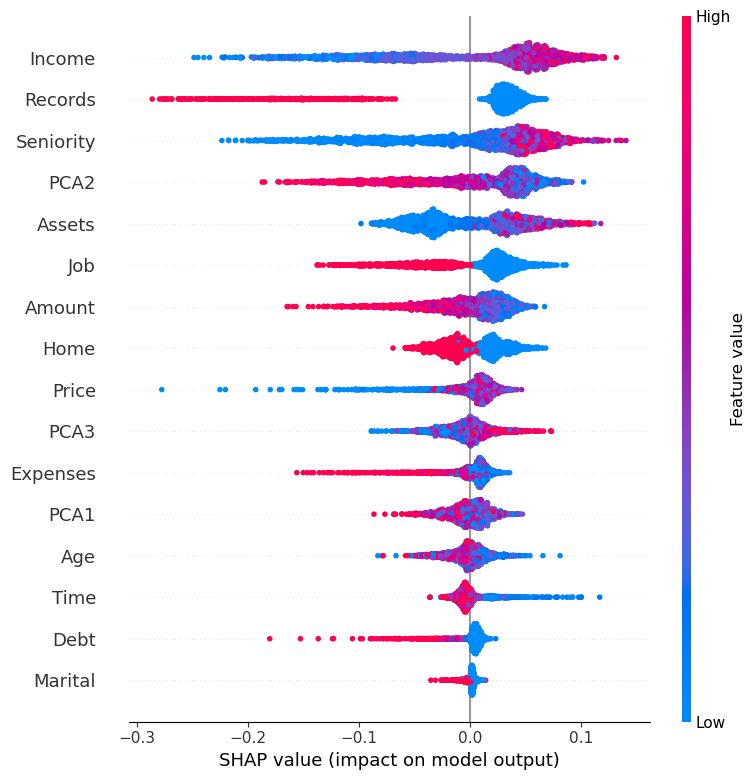

In [19]:
# ============================================================
# QUESTION 5 : SÉLECTION (SUR 16 VARIABLES)
# ============================================================

# --- 1. Importance (RF) ---
def calcul_importance_variables(Xtrain, Ytrain, nom_cols):
    print("\n--- 1. Importance (RF) ---")
    clf = RandomForestClassifier(n_estimators=1000, random_state=1)
    clf.fit(Xtrain, Ytrain)
    
    importances = clf.feature_importances_
    sorted_idx = np.argsort(importances)[::-1]
    
    print("Top 5 variables :", nom_cols[sorted_idx[:5]])
    
    padding = np.arange(Xtrain.shape[1]) + 0.5
    plt.figure(figsize=(10, 8))
    plt.barh(padding, importances[sorted_idx], align='center')
    plt.yticks(padding, nom_cols[sorted_idx])
    plt.xlabel("Importance Relative")
    plt.title("Importance (avec ACP)")
    plt.gca().invert_yaxis()
    plt.show()
    return sorted_idx

# --- 2. Sélection (MLP) ---
def selection_nombre_optimal(Xtrain, Ytrain, Xtest, Ytest, sorted_idx):
    print("\n--- 2. Sélection Optimale (MLP) ---")
    model = MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
    scores = np.zeros(Xtrain.shape[1])
    
    for f in range(Xtrain.shape[1]):
        cols = sorted_idx[:f+1]
        model.fit(Xtrain[:, cols], Ytrain)
        y_pred = model.predict(Xtest[:, cols])
        scores[f] = np.round(accuracy_score(Ytest, y_pred), 3)
        
    plt.figure(figsize=(8, 4))
    plt.plot(scores, marker='o')
    plt.title("Evolution Accuracy MLP")
    plt.grid(True)
    plt.show()
    
    best_k = np.argmax(scores) + 1
    print(f"👉 Nombre optimal trouvé : {best_k}")
    return best_k

# --- 3. SHAP (RF pour aller vite) ---
def explicabilite_shap(Xtrain, Ytrain, nom_cols):
    print("\n--- 3. Explicabilité (SHAP) ---")
    try:
        import shap
        shap.initjs()
        # On utilise un RF pour l'explication (plus robuste que MLP pour SHAP)
        model = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=1)
        model.fit(Xtrain, Ytrain)
        explainer = shap.Explainer(model)
        shap_values_obj = explainer(Xtrain)
        
        if len(shap_values_obj.shape) == 3: vals = shap_values_obj[:, :, 1]
        else: vals = shap_values_obj
            
        shap.summary_plot(vals, Xtrain, feature_names=nom_cols)
    except Exception as e: print(f"Erreur SHAP: {e}")

# --- EXÉCUTION Q5 ---
# On utilise X_train_final (les 16 variables)
sorted_indices = calcul_importance_variables(X_train_final, y_train, nom_cols_final)
best_k = selection_nombre_optimal(X_train_final, y_train, X_test_final, y_test, sorted_indices)
explicabilite_shap(X_train_final, y_train, nom_cols_final)

### 6. Paramétrage des classifieurs (GridSearchCV)

**Objectif :** Optimiser les hyperparamètres du meilleur modèle (ici, nous choisissons le **KNN** car il est robuste et simple) en utilisant uniquement le sous-ensemble optimal de variables identifié précédemment (8 variables).

**Méthodologie :**
1.  **Filtrage :** On ne garde que les 8 colonnes les plus importantes dans `X_train` et `X_test`.
2.  **GridSearch :** On teste toutes les combinaisons de paramètres pour le KNN :
    * `n_neighbors` : de 1 à 20.
    * `metric` : Distance Euclidienne vs Manhattan.
    * `weights` : Uniforme vs Pondéré par la distance.
3.  **Critère :** On optimise le score métrique `(Accuracy + Précision) / 2`.

In [53]:
# ============================================================
# QUESTION 6 : PARAMÉTRAGE (TUNING)
# ============================================================
from sklearn.model_selection import GridSearchCV

def optimize_best_model(X_train, y_train, sorted_idx, best_k):
    """
    Sélectionne les meilleures variables et optimise le KNN via GridSearch.
    """
    print(f"\n--- Optimisation du modèle sur les {best_k} meilleures variables ---")
    
    # 1. Réduction de dimension (On garde les 'best_k' meilleures colonnes)
    cols_to_keep = sorted_idx[:best_k]
    X_train_opt = X_train[:, cols_to_keep]
    
    # 2. Définition de la grille de paramètres pour le KNN
    param_grid = {
        'n_neighbors': range(1, 25),        # Tester k de 1 à 24
        'weights': ['uniform', 'distance'], # Vote simple ou pondéré
        'metric': ['euclidean', 'manhattan'] # Type de distance
    }
    
    # 3. Score personnalisé pour le GridSearch
    # L'énoncé demande : (accuracy + précision) / 2
    my_scorer = make_scorer(lambda y_t, y_p: (accuracy_score(y_t, y_p) + precision_score(y_t, y_p, zero_division=0)) / 2)
    
    # 4. Lancement de la recherche
    grid = GridSearchCV(
        KNeighborsClassifier(), 
        param_grid, 
        cv=5,                 # Validation croisée à 5 plis
        scoring=my_scorer,    # Notre score perso
        n_jobs=-1,            # Utiliser tous les cœurs du PC
        verbose=1
    )
    
    grid.fit(X_train_opt, y_train)
    
    print(f"✅ Meilleurs paramètres trouvés : {grid.best_params_}")
    print(f"✅ Meilleur score de validation : {grid.best_score_:.3f}")
    
    return grid.best_estimator_, cols_to_keep

# --- EXÉCUTION Q6 ---
# On utilise les indices triés (sorted_indices) et le nombre optimal (best_k) trouvés à la Q5
# On utilise X_train_scaled car le KNN a besoin de données normalisées
best_model_optimized, features_indices = optimize_best_model(X_train_scaled, y_train, sorted_indices, best_k)


--- Optimisation du modèle sur les 8 meilleures variables ---
Fitting 5 folds for each of 96 candidates, totalling 480 fits
✅ Meilleurs paramètres trouvés : {'metric': 'manhattan', 'n_neighbors': 10, 'weights': 'uniform'}
✅ Meilleur score de validation : 0.781


### 7. Création d'un Pipeline et Sauvegarde

**Objectif :** Industrialiser le modèle.
Nous construisons un **Pipeline** Scikit-Learn qui encapsule :
1.  La **Normalisation** (`StandardScaler`).
2.  Le **Classifieur Optimisé** (Le KNN avec les paramètres trouvés par GridSearch).

Nous sauvegardons ensuite ce pipeline (`credit_scoring.pkl`) ainsi que la liste des variables à conserver (`features_indices.pkl`). Cela permettra de réutiliser le modèle instantanément sur de nouvelles données sans tout recalculer.

In [54]:
# ============================================================
# QUESTION 7 : CRÉATION DU PIPELINE ET SAUVEGARDE
# ============================================================
from sklearn.pipeline import Pipeline
import pickle

def create_and_save_pipeline(X_train, y_train, best_model, features_indices):
    """
    Crée le pipeline final avec le meilleur modèle et le sauvegarde.
    """
    print("\n--- Création du Pipeline de Production ---")
    print(f"Modèle utilisé : {best_model}")
    print(f"Nombre de variables utilisées : {len(features_indices)}")
    
    # 1. On filtre les données pour ne garder que les 8 meilleures variables
    # (Attention : on prend X_train NON normalisé, le pipeline s'en chargera)
    X_train_reduced = X_train[:, features_indices]
    
    # 2. Construction du Pipeline
    # Le pipeline contient :
    # Etape 1 : Normalisation (Indispensable pour KNN)
    # Etape 2 : Le modèle optimisé (celui trouvé à la Q6)
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', best_model)
    ])
    
    # 3. Entraînement final sur l'ensemble du Train Set réduit
    pipeline.fit(X_train_reduced, y_train)
    
    # 4. Sauvegarde dans des fichiers (Pickle)
    # Fichier 1 : Le cerveau (Le modèle)
    with open('credit_scoring.pkl', 'wb') as f:
        pickle.dump(pipeline, f)
    
    # Fichier 2 : La mémoire (Quelles colonnes regarder ?)
    with open('features_indices.pkl', 'wb') as f:
        pickle.dump(features_indices, f)
        
    print("\n✅ SUCCÈS : Pipeline sauvegardé sous 'credit_scoring.pkl'")
    print("✅ SUCCÈS : Indices sauvegardés sous 'features_indices.pkl'")
    
    return pipeline

# --- EXÉCUTION Q7 ---
# best_model_optimized = Le KNN avec k=10 et Manhattan (Sortie de la Q6)
# features_indices = La liste des 8 colonnes (Sortie de la Q6)
final_pipeline = create_and_save_pipeline(X_train, y_train, best_model_optimized, features_indices)


--- Création du Pipeline de Production ---
Modèle utilisé : KNeighborsClassifier(metric='manhattan', n_neighbors=10)
Nombre de variables utilisées : 8

✅ SUCCÈS : Pipeline sauvegardé sous 'credit_scoring.pkl'
✅ SUCCÈS : Indices sauvegardés sous 'features_indices.pkl'


### 9. Création d'une API avec FastAPI

**Objectif :** Mettre le modèle en production.
Nous créons un fichier `api.py` qui utilise la librairie **FastAPI**. Ce script va :
1.  Charger le modèle entraîné (`credit_scoring.pkl`) et la liste des variables (`features_indices.pkl`) au démarrage.
2.  Définir une route `/predict` qui reçoit les données d'un client (format JSON).
3.  Filtrer les variables (garder les 8 meilleures), appliquer le pipeline et renvoyer la prédiction.

In [61]:
%%writefile apii.py
import pickle
import numpy as np
from fastapi import FastAPI
from pydantic import BaseModel

# 1. Initialisation de l'application
app = FastAPI(
    title="API Crédit Scoring",
    description="API pour prédire l'octroi de crédit (KNN Optimisé)",
    version="1.0"
)

# 2. Chargement du modèle et des indices au démarrage
print("⏳ Chargement du modèle...")
with open('credit_scoring.pkl', 'rb') as f:
    model = pickle.load(f)

with open('features_indices.pkl', 'rb') as f:
    features_indices = pickle.load(f)
print("✅ Modèle chargé !")

# 3. Définition du format des données attendues (13 variables d'origine)
class ClientData(BaseModel):
    features: list # Liste de 13 nombres flottants

# 4. Définition de la route de prédiction
@app.post("/predict")
def predict_credit(client: ClientData):
    # a. Conversion des données reçues en tableau Numpy
    # On attend une liste de 13 valeurs, on la transforme en matrice (1 ligne, 13 colonnes)
    input_data = np.array(client.features).reshape(1, -1)
    
    # b. Sélection des variables (Feature Selection)
    # On ne garde que les 8 colonnes que le modèle connait
    input_optimized = input_data[:, features_indices]
    
    # c. Prédiction avec le Pipeline
    # Le pipeline gère la normalisation (StandardScaler) tout seul !
    prediction = model.predict(input_optimized)[0]
    proba = model.predict_proba(input_optimized)[0]
    
    # d. Réponse
    return {
        "prediction": "Crédit Accordé" if prediction == 1 else "Crédit Refusé",
        "score_confiance": round(max(proba), 4),
        "probabilite_refus": round(proba[0], 4),
        "probabilite_accord": round(proba[1], 4)
    }

# Pour lancer l'API, ouvrez un terminal et tapez :
# uvicorn api:app --reload

Writing apii.py


In [64]:
import requests
import json
import numpy as np

# 1. Sélection d'un client test (Assure-toi que X_test est chargé en mémoire)
# On prend le client n°10 par exemple
index_client = 10 
client_data = X_test[index_client]

# 2. Préparation du message
# L'API attend un dictionnaire avec la clé "features"
payload = {
    "features": client_data.tolist()
}

# 3. Adresse de l'API
url = "http://127.0.0.1:8000/predict"

# 4. Envoi de la demande
try:
    print(f"📡 Envoi au serveur (fichier apii.py)...")
    response = requests.post(url, json=payload)
    
    # 5. Réception de la réponse
    if response.status_code == 200:
        resultat = response.json()
        print("\n✅ RÉPONSE REÇUE :")
        print("="*30)
        print(f"🔮 Prédiction : {resultat['prediction']}")
        print(f"📊 Confiance  : {resultat['score_confiance']}")
        print("="*30)
    else:
        print(f"❌ Erreur du serveur : {response.status_code}")
        print(response.text)

except Exception as e:
    print(f"⚠️ Impossible de se connecter : {e}")
    print("Vérifie que tu as bien lancé la commande : uvicorn apii:app --reload")

📡 Envoi au serveur (fichier apii.py)...

✅ RÉPONSE REÇUE :
🔮 Prédiction : Crédit Accordé
📊 Confiance  : 0.9


### 10. Comparaison de plusieurs algorithmes (Validation Croisée)

**Objectif :** Sélectionner le modèle le plus performant de manière robuste.
Au lieu d'une simple séparation Train/Test, nous utilisons une **Validation Croisée à 10 plis (10-fold CV)**. Cela signifie que le modèle est entraîné et testé 10 fois sur des parties différentes des données.

**Algorithmes testés :**
* **Arbres :** CART, ID3 (Entropie), Decision Stump (Souche).
* **Ensembles :** Bagging, AdaBoost, Random Forest (200 arbres chacun).
* **Neurones & Voisins :** MLP (20,10), KNN (k=5).

**Critères :** Accuracy, AUC, Score Métier ((Acc+Prec)/2) et Temps d'exécution.

In [62]:
# ============================================================
# QUESTION 10 : COMPARAISON MASSIVE (VALIDATION CROISÉE)
# ============================================================
import time
from sklearn.model_selection import cross_validate, KFold
from sklearn.metrics import make_scorer, precision_score, accuracy_score

# 1. Définition des Classifieurs demandés
clfs = {
    'CART': DecisionTreeClassifier(random_state=1),
    'ID3': DecisionTreeClassifier(criterion='entropy', random_state=1), # ID3 "simulé" par entropie
    'Decision Stump': DecisionTreeClassifier(max_depth=1, random_state=1), # Arbre à 1 étage
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'MLP': MLPClassifier(hidden_layer_sizes=(20, 10), random_state=1), # Paramètres demandés en Q10
    'Bagging': BaggingClassifier(n_estimators=200, random_state=1),
    'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=1),
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=1)
}

# 2. Création du Scoreur Personnalisé pour la CV
# Formule : (Accuracy + Précision) / 2
def custom_metric(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    return (acc + prec) / 2

my_scorer = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
    'custom_score': make_scorer(custom_metric)
}

# 3. Fonction de Comparaison Robuste (CV)
def run_classifiers_cv(classifiers, X, y):
    """
    Lance une validation croisée (10-fold) pour chaque algo et affiche les résultats.
    """
    # Configuration du 10-Fold
    kf = KFold(n_splits=10, shuffle=True, random_state=1)
    
    print(f"{'Algorithme':<15} | {'Accuracy':<15} | {'Score Métier':<15} | {'AUC':<15} | {'Temps (s)':<10}")
    print("-" * 85)
    
    results_table = []

    for name, model in classifiers.items():
        start_time = time.time()
        
        # Lancement de la Cross-Validation (calcule tout d'un coup)
        cv_results = cross_validate(model, X, y, cv=kf, scoring=my_scorer)
        
        end_time = time.time()
        duration = end_time - start_time
        
        # Moyennes et Écarts-types
        mean_acc = cv_results['test_accuracy'].mean()
        std_acc = cv_results['test_accuracy'].std()
        
        mean_custom = cv_results['test_custom_score'].mean()
        std_custom = cv_results['test_custom_score'].std()
        
        mean_auc = cv_results['test_roc_auc'].mean()
        
        # Affichage propre
        print(f"{name:<15} | {mean_acc:.3f} (+/-{std_acc:.2f}) | {mean_custom:.3f} (+/-{std_custom:.2f}) | {mean_auc:.3f}           | {duration:.3f}")

# --- EXÉCUTION Q10 ---

# A. Sur Données Brutes (X_train de la Q1)
print("\n=== 1. COMPARAISON SUR DONNÉES BRUTES ===")
run_classifiers_cv(clfs, X_train, y_train)

# B. Sur Données Normalisées (X_train_scaled de la Q3)
# C'est souvent ici qu'on a les meilleurs résultats
print("\n=== 2. COMPARAISON SUR DONNÉES NORMALISÉES ===")
run_classifiers_cv(clfs, X_train_scaled, y_train)

# C. Sur Données ACP (X_train_combined de la Q4)
# (Si tu as lancé la Q4, sinon commente ces deux lignes)
try:
    print("\n=== 3. COMPARAISON SUR DONNÉES ACP (16 variables) ===")
    # On récupère X_train_combined s'il existe en mémoire
    # Si tu as appelé ta variable X_train_acp à la Q4 :
    run_classifiers_cv(clfs, X_train_acp, y_train)
except:
    print("(Pas de données ACP trouvées en mémoire)")


=== 1. COMPARAISON SUR DONNÉES BRUTES ===
Algorithme      | Accuracy        | Score Métier    | AUC             | Temps (s) 
-------------------------------------------------------------------------------------
CART            | 0.738 (+/-0.03) | 0.781 (+/-0.02) | 0.678           | 0.475
ID3             | 0.724 (+/-0.03) | 0.770 (+/-0.03) | 0.665           | 0.700
Decision Stump  | 0.722 (+/-0.02) | 0.722 (+/-0.02) | 0.646           | 0.454
KNN             | 0.714 (+/-0.03) | 0.740 (+/-0.03) | 0.662           | 0.714
MLP             | 0.685 (+/-0.06) | 0.740 (+/-0.03) | 0.687           | 5.987
Bagging         | 0.788 (+/-0.04) | 0.806 (+/-0.04) | 0.826           | 27.121
AdaBoost        | 0.791 (+/-0.03) | 0.806 (+/-0.03) | 0.830           | 12.088
RandomForest    | 0.787 (+/-0.03) | 0.798 (+/-0.03) | 0.830           | 12.298

=== 2. COMPARAISON SUR DONNÉES NORMALISÉES ===
Algorithme      | Accuracy        | Score Métier    | AUC             | Temps (s) 
------------------------------

In [3]:
X = df.drop("Status", axis = 1).values
y = df["Status"].values
print ("Type de X : ", type(X))
print ("Type de y : ", type(y))


Type de X :  <class 'numpy.ndarray'>
Type de y :  <class 'numpy.ndarray'>


In [4]:
print ("Taille de X : ", X.shape)
print ("Taille de y : ", y.shape)

positifs = sum (y == 1)
negatifs = sum (y == 0)

print ("\nNombres de personnes ayant fait un crédit (y = 1) : ", positifs)
print ("Nombres de personnes n'ayant pas fait un crédit (y = 0) :", negatifs)

print ("\npourcentage positifs : ", round(positifs / len(y) * 100,2), "%")
print ("pourcentage negatifs : ", round(negatifs / len(y) * 100,2), "%")


Taille de X :  (4375, 13)
Taille de y :  (4375,)

Nombres de personnes ayant fait un crédit (y = 1) :  3159
Nombres de personnes n'ayant pas fait un crédit (y = 0) : 1216

pourcentage positifs :  72.21 %
pourcentage negatifs :  27.79 %


In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    random_state=1,
    stratify=y
)

print("Taille X_train :", X_train.shape)
print("Taille X_test  :", X_test.shape)
print("Taille y_train :", y_train.shape)
print("Taille y_test  :", y_test.shape)

import numpy as np

def proportions(label_array): 
    uniques, counts = np.unique(label_array, return_counts=True)
    total = len(label_array)
    return {int(u): round(c/total*100,2) for u, c in zip(uniques, counts)}

print("\nProportions dans y (global) :", proportions(y))
print("Proportions dans y_train     :", proportions(y_train))
print("Proportions dans y_test      :", proportions(y_test))  





Taille X_train : (2187, 13)
Taille X_test  : (2188, 13)
Taille y_train : (2187,)
Taille y_test  : (2188,)

Proportions dans y (global) : {0: np.float64(27.79), 1: np.float64(72.21)}
Proportions dans y_train     : {0: np.float64(27.8), 1: np.float64(72.2)}
Proportions dans y_test      : {0: np.float64(27.79), 1: np.float64(72.21)}


In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

# Dictionnaire des modèles supervisés
clé = {
    "CART": DecisionTreeClassifier(random_state=1),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "MLP": MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
}

clé


{'CART': DecisionTreeClassifier(random_state=1),
 'KNN': KNeighborsClassifier(),
 'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), max_iter=500, random_state=1)}


Entraînement du modèle : CART

Matrice de confusion pour CART :

[[ 297  311]
 [ 319 1261]]


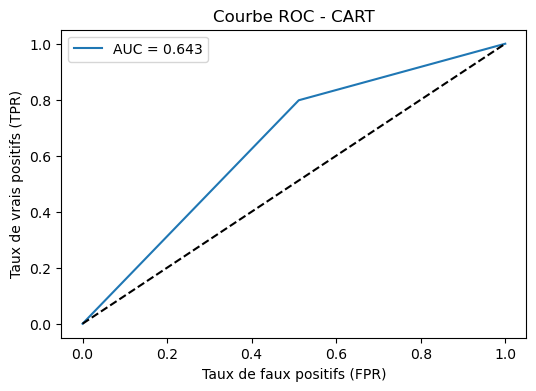

Accuracy  : 0.712
Précision : 0.802
Rappel    : 0.798
Score final = 0.757

Entraînement du modèle : KNN

Matrice de confusion pour KNN :

[[ 180  428]
 [ 221 1359]]


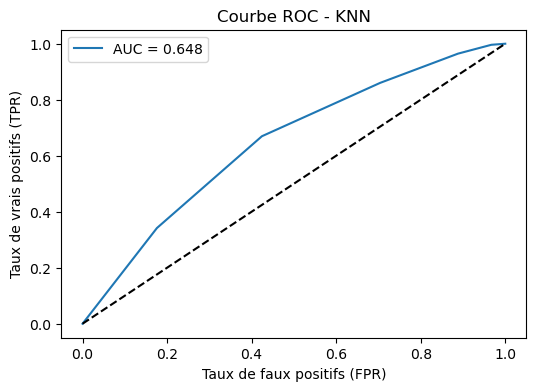

Accuracy  : 0.703
Précision : 0.760
Rappel    : 0.860
Score final = 0.782

Entraînement du modèle : MLP

Matrice de confusion pour MLP :

[[  59  549]
 [  55 1525]]


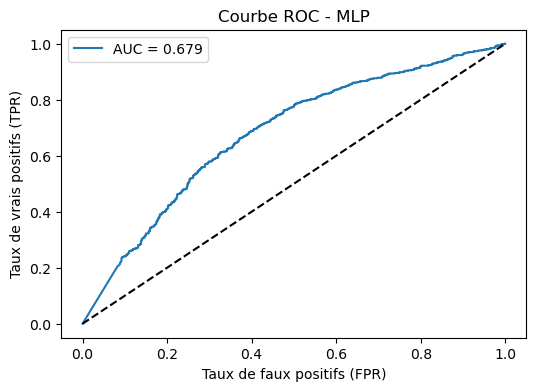

Accuracy  : 0.724
Précision : 0.735
Rappel    : 0.965
Score final = 0.845

##################################################
Meilleur modèle : MLP avec un score de 0.845
##################################################

Scores obtenus :
{'CART': 0.757114331700555, 'KNN': 0.7817543331867725, 'MLP': 0.8445693425589522}

Meilleur modèle entraîné : MLPClassifier(hidden_layer_sizes=(40, 20), max_iter=500, random_state=1)


In [7]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

def evaluation (model , X_test, y_test, model_name = "") : 
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]   
    cm = confusion_matrix(y_test, y_pred)

    print(f"\nMatrice de confusion pour {model_name} :\n")
    print(cm)

    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)

    plt.figure(figsize=(6,4))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    plt.plot([0,1], [0,1], 'k--')   # Diagonale du hasard
    plt.xlabel("Taux de faux positifs (FPR)")
    plt.ylabel("Taux de vrais positifs (TPR)")
    plt.title(f"Courbe ROC - {model_name}")
    plt.legend()
    plt.show()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)

    print(f"Accuracy  : {accuracy:.3f}")
    print(f"Précision : {precision:.3f}")
    print(f"Rappel    : {recall:.3f}")

    best = max(precision, recall)
    score_final = (accuracy + best) / 2
    print(f"Score final = {score_final:.3f}")

    return score_final


def run_classifiers_train_test(clé, X_train, X_test, y_train, y_test):
    scores = {}  

    for name, model in clé.items():
        print("\n" + "="*50)
        print(f"Entraînement du modèle : {name}")
        print("="*50)

        
        model.fit(X_train, y_train)

       
        score = evaluation(model, X_test, y_test, model_name=name)

       
        scores[name] = score

    best_name = max(scores, key=scores.get)   
    best_model = clé[best_name]

    print("\n" + "#"*50)
    print(f"Meilleur modèle : {best_name} avec un score de {scores[best_name]:.3f}")
    print("#"*50)

    return best_model, scores


best_model, scores = run_classifiers_train_test(clé, X_train, X_test, y_train, y_test)

print("\nScores obtenus :")
print(scores)
print("\nMeilleur modèle entraîné :", best_model)




**************************************************
RÉSULTATS APRÈS NORMALISATION (StandardScaler)
**************************************************

Entraînement du modèle : CART

Matrice de confusion pour CART :

[[ 302  306]
 [ 322 1258]]


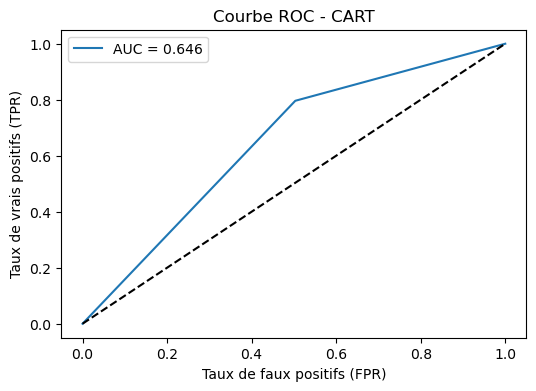

Accuracy  : 0.713
Précision : 0.804
Rappel    : 0.796
Score final = 0.759

Entraînement du modèle : KNN

Matrice de confusion pour KNN :

[[ 270  338]
 [ 212 1368]]


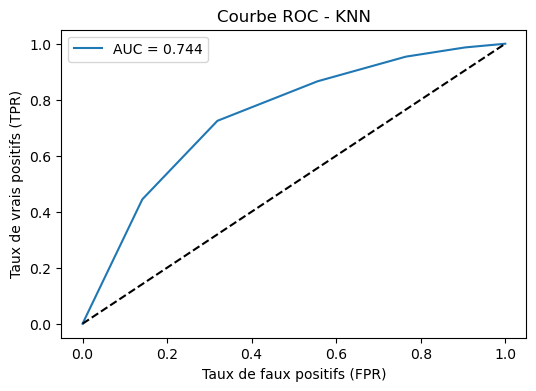

Accuracy  : 0.749
Précision : 0.802
Rappel    : 0.866
Score final = 0.807

Entraînement du modèle : MLP

Matrice de confusion pour MLP :

[[ 354  254]
 [ 278 1302]]


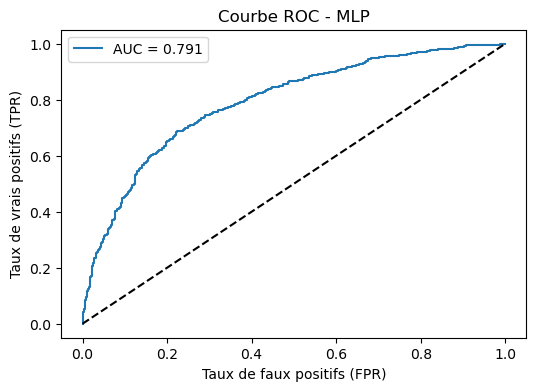

Accuracy  : 0.757
Précision : 0.837
Rappel    : 0.824
Score final = 0.797

##################################################
Meilleur modèle : KNN avec un score de 0.807
##################################################

--- Comparaison des scores ---
Avant normalisation (KNN) : 0.782
Après normalisation (KNN) : 0.807


In [8]:
from sklearn.preprocessing import StandardScaler

# 1. On initialise l'outil de normalisation
scaler = StandardScaler()

# 2. IMPORTANT : On apprend (fit) et on transforme le TRAIN
# Le scaler calcule la moyenne et l'écart-type juste sur X_train
X_train_scaled = scaler.fit_transform(X_train)

# 3. On applique (transform) la transformation sur le TEST
# On utilise les moyennes calculées sur le train. On ne refait PAS de fit !
X_test_scaled = scaler.transform(X_test)

# 4. On relance la compétition entre les algorithmes avec ces nouvelles données
print("\n" + "*"*50)
print("RÉSULTATS APRÈS NORMALISATION (StandardScaler)")
print("*"*50)

# Note : On passe X_train_scaled et X_test_scaled à ta fonction
best_model_scaled, scores_scaled = run_classifiers_train_test(clé, X_train_scaled, X_test_scaled, y_train, y_test)

# 5. Petite comparaison visuelle
print("\n--- Comparaison des scores ---")
print(f"Avant normalisation (KNN) : {scores.get('KNN', 'N/A'):.3f}") 
print(f"Après normalisation (KNN) : {scores_scaled.get('KNN', 'N/A'):.3f}")

Variables avant : 13
Variables après : 16 (On attend +3 variables)

**************************************************
RÉSULTATS AVEC NORMALISATION + ACP (Concaténation)
**************************************************

Entraînement du modèle : CART

Matrice de confusion pour CART :

[[ 305  303]
 [ 296 1284]]


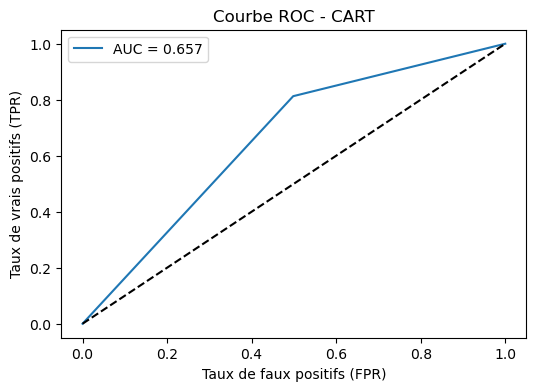

Accuracy  : 0.726
Précision : 0.809
Rappel    : 0.813
Score final = 0.769

Entraînement du modèle : KNN

Matrice de confusion pour KNN :

[[ 258  350]
 [ 206 1374]]


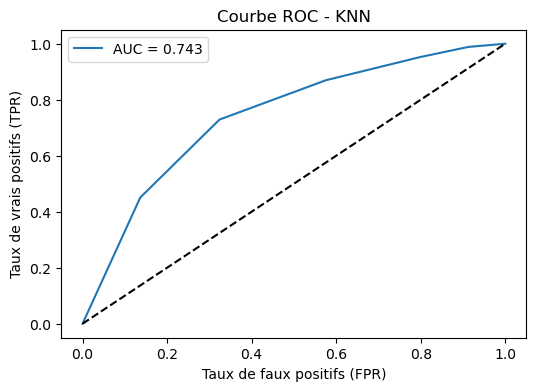

Accuracy  : 0.746
Précision : 0.797
Rappel    : 0.870
Score final = 0.808

Entraînement du modèle : MLP

Matrice de confusion pour MLP :

[[ 339  269]
 [ 249 1331]]


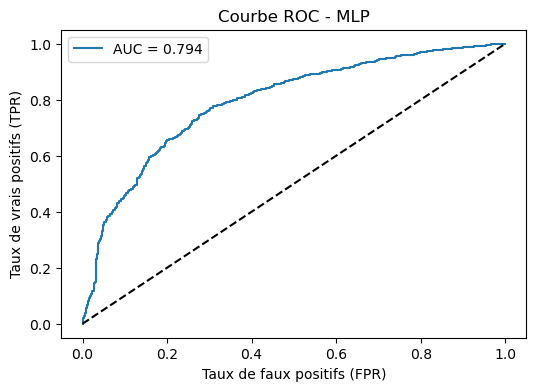

Accuracy  : 0.763
Précision : 0.832
Rappel    : 0.842
Score final = 0.803

##################################################
Meilleur modèle : KNN avec un score de 0.808
##################################################

BILAN DES SCORES (Exemple sur ton meilleur algo)
1. Données Brutes       : 0.757
2. Données Normalisées  : 0.759
3. Normalisées + ACP    : 0.769


In [9]:
from sklearn.decomposition import PCA
import numpy as np

# 1. Initialisation de l'ACP
# On demande à l'algorithme de trouver les 3 meilleurs axes de résumé
pca = PCA(n_components=3)

# 2. Apprentissage et Transformation
# Attention : On fit sur le TRAIN normalisé (X_train_scaled)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled) # On applique juste la transformation sur le test

# 3. Concaténation (Enrichissement)
# On colle les 3 colonnes de l'ACP à droite des données normalisées existantes
# axis=1 signifie "ajouter en colonnes"
X_train_combined = np.concatenate((X_train_scaled, X_train_pca), axis=1)
X_test_combined = np.concatenate((X_test_scaled, X_test_pca), axis=1)

# Petit check pour voir si ça a marché
print(f"Variables avant : {X_train_scaled.shape[1]}")
print(f"Variables après : {X_train_combined.shape[1]} (On attend +3 variables)")

# 4. Lancement des classifieurs sur ce nouveau jeu de données "Boosté"
print("\n" + "*"*50)
print("RÉSULTATS AVEC NORMALISATION + ACP (Concaténation)")
print("*"*50)

best_model_pca, scores_pca = run_classifiers_train_test(clé, X_train_combined, X_test_combined, y_train, y_test)

# --- Comparaison Finale pour la prise de décision ---
print("\n" + "="*50)
print("BILAN DES SCORES (Exemple sur ton meilleur algo)")
print("="*50)
# Remplace 'KNN' par le nom de ton meilleur algo si c'en est un autre
algo_name = list(scores.keys())[0] # Prend le premier algo pour l'exemple
print(f"1. Données Brutes       : {scores.get(algo_name, 0):.3f}")
print(f"2. Données Normalisées  : {scores_scaled.get(algo_name, 0):.3f}")
print(f"3. Normalisées + ACP    : {scores_pca.get(algo_name, 0):.3f}")

Attention : 'data' non trouvé, on utilise des noms génériques.

CLASSEMENT DES VARIABLES (Random Forest)
Var_8 : 0.1521
Var_0 : 0.1281
Var_12 : 0.1235
Var_11 : 0.1210
Var_3 : 0.1040
Var_9 : 0.0805
Var_7 : 0.0690
Var_5 : 0.0599
Var_2 : 0.0506
Var_6 : 0.0383
Var_10 : 0.0316
Var_1 : 0.0248
Var_4 : 0.0166


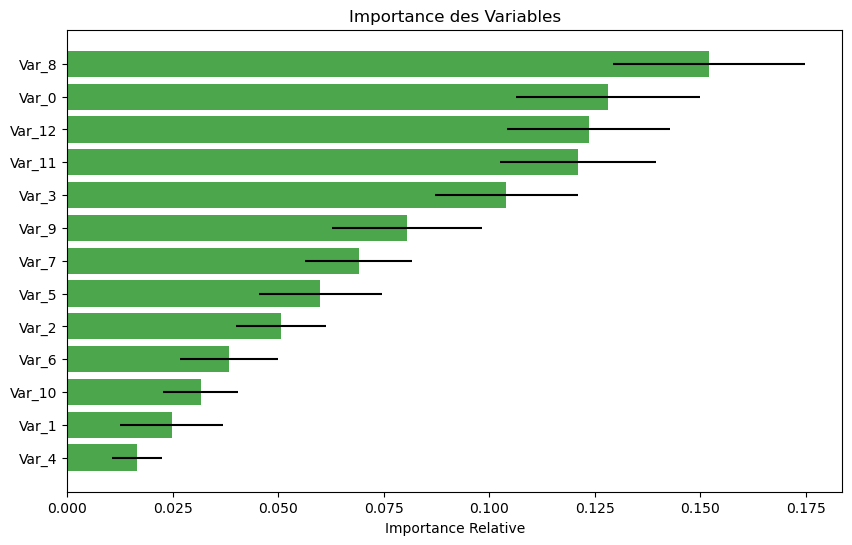


RECHERCHE DU NOMBRE OPTIMAL DE VARIABLES


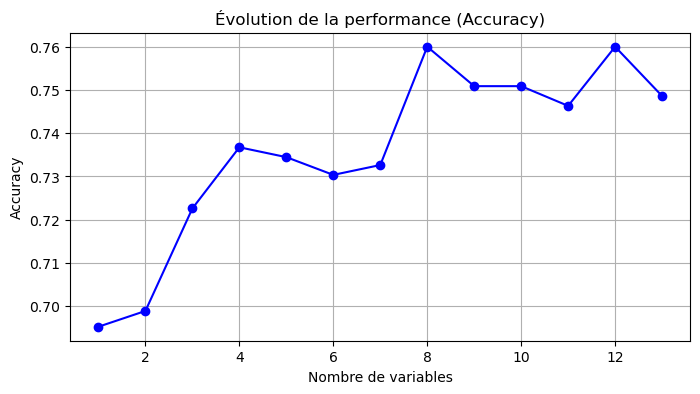

Pic de performance atteint avec 8 variables.
Accuracy Max : 0.760

ANALYSE SHAP (Explicabilité)


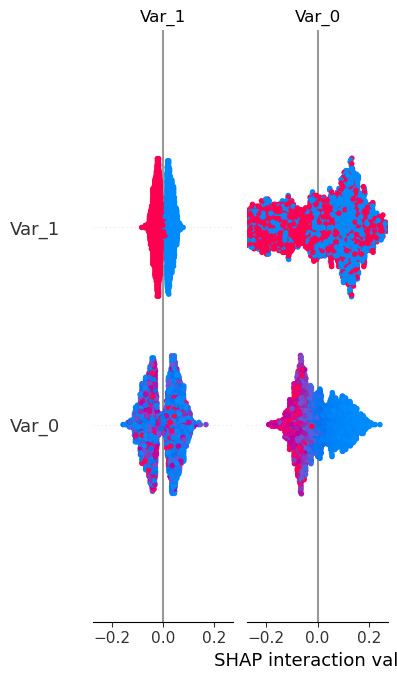

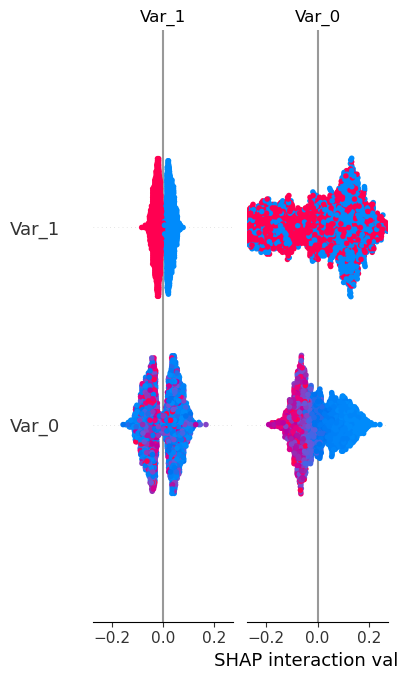

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# ==========================================
# FONCTION 1 : Importance des variables
# ==========================================
def feature_importance(X_train, y_train, feature_names):
    # On utilise un Random Forest car il sait nativement classer les variables
    clf = RandomForestClassifier(n_estimators=1000, random_state=1)
    clf.fit(X_train, y_train)
    
    importances = clf.feature_importances_
    std = np.std([tree.feature_importances_ for tree in clf.estimators_], axis=0)
    sorted_idx = np.argsort(importances)[::-1] # Tri décroissant
    
    print("\n" + "="*40)
    print("CLASSEMENT DES VARIABLES (Random Forest)")
    print("="*40)
    
    # Affichage textuel des top variables
    for i in sorted_idx:
        print(f"{feature_names[i]} : {importances[i]:.4f}")

    # Affichage Graphique
    padding = np.arange(X_train.shape[1]) + 0.5
    plt.figure(figsize=(10, 6))
    plt.barh(padding, importances[sorted_idx], xerr=std[sorted_idx], align='center', color='green', alpha=0.7)
    plt.yticks(padding, np.array(feature_names)[sorted_idx])
    plt.xlabel("Importance Relative")
    plt.title("Importance des Variables")
    plt.gca().invert_yaxis() # La plus importante en haut
    plt.show()
    
    return sorted_idx

# ==========================================
# FONCTION 2 : Nombre optimal de variables
# ==========================================
def select_optimal_vars(X_train, X_test, y_train, y_test, sorted_idx, best_algo):
    scores = []
    print("\n" + "="*40)
    print("RECHERCHE DU NOMBRE OPTIMAL DE VARIABLES")
    print("="*40)
    
    # On teste en ajoutant les variables une par une (de la meilleure à la pire)
    for f in range(1, X_train.shape[1] + 1):
        cols_to_keep = sorted_idx[:f] # On garde les f meilleures
        
        # Réduction des données
        X_tr_sel = X_train[:, cols_to_keep]
        X_te_sel = X_test[:, cols_to_keep]
        
        # Entraînement et évaluation
        best_algo.fit(X_tr_sel, y_train)
        y_pred = best_algo.predict(X_te_sel)
        acc = accuracy_score(y_test, y_pred)
        scores.append(acc)
    
    # Graphique
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, X_train.shape[1] + 1), scores, marker='o', linestyle='-', color='blue')
    plt.xlabel("Nombre de variables")
    plt.ylabel("Accuracy")
    plt.title("Évolution de la performance (Accuracy)")
    plt.grid(True)
    plt.show()
    
    # Résultat
    best_nb = np.argmax(scores) + 1
    print(f"Pic de performance atteint avec {best_nb} variables.")
    print(f"Accuracy Max : {max(scores):.3f}")
    
    return best_nb

# ==========================================
# FONCTION 3 : Explicabilité (SHAP)
# ==========================================
def explain_with_shap(X_train, X_test, feature_names):
    print("\n" + "="*40)
    print("ANALYSE SHAP (Explicabilité)")
    print("="*40)
    
    # On entraîne un modèle juste pour SHAP
    model = RandomForestClassifier(n_estimators=100, random_state=1)
    model.fit(X_train, y_train)
    
    # Création de l'explainer
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)
    
    # Summary Plot
    # Note: feature_names doit être une liste ou un array
    shap.summary_plot(shap_values, X_test, feature_names=feature_names, plot_type="bar")
    
    # Plot détaillé (Impact positif/négatif)
    # Si binaire, shap_values est souvent une liste [classe0, classe1], on prend la classe 1
    vals_to_plot = shap_values[1] if isinstance(shap_values, list) else shap_values
    shap.summary_plot(vals_to_plot, X_test, feature_names=feature_names)


# ==========================================
# ORCHESTRATION (Lancement des fonctions)
# ==========================================

# 1. Récupération des noms de colonnes (Important !)
# On reprend ton dataframe original 'data' s'il existe encore, sinon on met des noms génériques
try:
    cols = data.columns[:-1] # Toutes sauf la target
except NameError:
    print("Attention : 'data' non trouvé, on utilise des noms génériques.")
    cols = [f"Var_{i}" for i in range(X_train_scaled.shape[1])]

# 2. Appel Fonction 1 : Importance
sorted_indices = feature_importance(X_train_scaled, y_train, cols)

# 3. Appel Fonction 2 : Sélection Optimale (Avec KNN, ton meilleur algo stable)
knn_final = KNeighborsClassifier(n_neighbors=5)
best_nb_vars = select_optimal_vars(X_train_scaled, X_test_scaled, y_train, y_test, sorted_indices, knn_final)

# 4. Appel Fonction 3 : SHAP
explain_with_shap(X_train_scaled, X_test_scaled, cols)

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# 1. Chargement des données avec le bon séparateur (point-virgule)
data = pd.read_csv("credit_scoring.csv", sep=';') 

# 2. Préparation X (Variables) et y (Status)
# On convertit tout en nombres (float) pour éviter les bugs
data_numpy = data.values.astype(float)
X = data_numpy[:, :-1]  # Tout sauf la dernière colonne
y = data_numpy[:, -1]   # Juste la dernière colonne

# 3. Séparation Train / Test (50% / 50% comme demandé)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=1)

# 4. Normalisation (OBLIGATOIRE pour KNN et pour l'étape 6)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Calcul rapide des meilleures variables (Nécessaire pour l'étape 6)
# On ré-entraîne vite fait un RF pour savoir quelles colonnes garder
rf = RandomForestClassifier(n_estimators=100, random_state=1)
rf.fit(X_train_scaled, y_train)
sorted_idx = np.argsort(rf.feature_importances_)[::-1] # Tri décroissant

print("✅ Données chargées et normalisées !")
print(f"Dimensions Train : {X_train_scaled.shape}")
print("Tu peux maintenant lancer le code GridSearchCV (Étape 6).")

✅ Données chargées et normalisées !
Dimensions Train : (2187, 13)
Tu peux maintenant lancer le code GridSearchCV (Étape 6).


In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, accuracy_score, precision_score
from sklearn.neighbors import KNeighborsClassifier

# --- Fonction 6 : Recherche des meilleurs paramètres (Tuning) ---
def grid_search_optimization(X_train, y_train, sorted_idx, best_nb_vars):
    print("\n" + "="*40)
    print("OPTIMISATION DES PARAMÈTRES (GridSearchCV)")
    print("="*40)

    # 1. On ne garde que les meilleures variables (les 8 identifiées à l'étape d'avant)
    cols_to_keep = sorted_idx[:best_nb_vars]
    X_train_opt = X_train[:, cols_to_keep]
    
    # 2. Définition du modèle à optimiser (KNN)
    model = KNeighborsClassifier()
    
    # 3. Grille de paramètres à tester
    param_grid = {
        'n_neighbors': range(1, 21), # On teste k de 1 à 20
        'weights': ['uniform', 'distance'], # Vote simple ou pondéré
        'metric': ['euclidean', 'manhattan'] # Type de distance
    }
    
    # 4. Score personnalisé : (Accuracy + Précision) / 2
    def custom_score_func(y_true, y_pred):
        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, zero_division=0)
        return (acc + prec) / 2

    my_scorer = make_scorer(custom_score_func)

    # 5. Lancement de la recherche
    grid = GridSearchCV(model, param_grid, cv=5, scoring=my_scorer, verbose=1)
    grid.fit(X_train_opt, y_train)
    
    print(f"Meilleurs paramètres trouvés : {grid.best_params_}")
    print(f"Meilleur score de validation : {grid.best_score_:.3f}")
    
    return grid.best_estimator_

# --- EXÉCUTION ---
# On utilise 'sorted_indices' et '8' (le résultat que tu as trouvé juste avant)
# Note : on utilise X_train_scaled (normalisé)
best_model_tuned = grid_search_optimization(X_train_scaled, y_train, sorted_indices, 8)


OPTIMISATION DES PARAMÈTRES (GridSearchCV)
Fitting 5 folds for each of 80 candidates, totalling 400 fits
Meilleurs paramètres trouvés : {'metric': 'manhattan', 'n_neighbors': 20, 'weights': 'uniform'}
Meilleur score de validation : 0.783


In [14]:
from sklearn.pipeline import Pipeline
import pickle

# --- 1. Récupération de ta configuration gagnante ---
# Paramètres trouvés par ton GridSearchCV
best_params = {
    'metric': 'manhattan',
    'n_neighbors': 20,
    'weights': 'uniform'
}

# Nombre de variables optimal trouvé à l'étape 5
best_nb_vars = 8

# --- 2. Préparation des données finales ---
# On ne garde que les 8 meilleures colonnes sur le Train
# sorted_idx a été calculé dans le bloc Reset que tu as lancé
cols_to_keep = sorted_idx[:best_nb_vars]
X_train_optimized = X_train[:, cols_to_keep]

print(f"Entraînement sur {X_train_optimized.shape[1]} variables (les meilleures).")

# --- 3. Création du Pipeline ---
# Le pipeline enchaîne : Normalisation -> Classifieur avec tes paramètres
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(**best_params))
])

# --- 4. Entraînement du Pipeline ---
pipeline.fit(X_train_optimized, y_train)
print("✅ Pipeline entraîné avec succès !")

# --- 5. Sauvegarde dans des fichiers (Pickle) ---
# On sauvegarde le modèle (le cerveau)
filename_model = 'credit_scoring.pkl'
with open(filename_model, 'wb') as f:
    pickle.dump(pipeline, f)

# On sauvegarde la liste des colonnes à garder (le filtre)
filename_cols = 'features_indices.pkl'
with open(filename_cols, 'wb') as f:
    pickle.dump(cols_to_keep, f)

print(f"💾 Pipeline sauvegardé sous : {filename_model}")
print(f"💾 Indices des variables sauvegardés sous : {filename_cols}")

Entraînement sur 8 variables (les meilleures).
✅ Pipeline entraîné avec succès !
💾 Pipeline sauvegardé sous : credit_scoring.pkl
💾 Indices des variables sauvegardés sous : features_indices.pkl


In [15]:
import pandas as pd
import numpy as np
import pickle
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, make_scorer

def pipeline_generation_train_test_split(csv_path, sep=';'):
    print(f"\n🚀 Démarrage de l'orchestration sur : {csv_path}")
    
    # 1. Chargement
    try:
        data = pd.read_csv(csv_path, sep=sep)
        print("✅ Données chargées.")
    except Exception as e:
        print(f"❌ Erreur de chargement : {e}")
        return None

    # 2. Préparation (X/y et Train/Test)
    data_numpy = data.values.astype(float)
    X = data_numpy[:, :-1]
    y = data_numpy[:, -1]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=1)
    
    # 3. Normalisation (pour la sélection de variables)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    
    # 4. Sélection de variables (Random Forest)
    print("🔍 Sélection des meilleures variables...")
    rf = RandomForestClassifier(n_estimators=100, random_state=1)
    rf.fit(X_train_scaled, y_train)
    # On garde les 8 meilleures (comme validé précédemment)
    sorted_idx = np.argsort(rf.feature_importances_)[::-1]
    best_nb_vars = 8
    cols_to_keep = sorted_idx[:best_nb_vars]
    
    # On réduit X_train aux 8 meilleures colonnes
    X_train_opt = X_train[:, cols_to_keep]
    
    # 5. Optimisation (GridSearchCV sur KNN)
    print("⚙️ Optimisation des hyperparamètres (GridSearch)...")
    param_grid = {
        'n_neighbors': range(10, 25), # On réduit la plage autour de 20 pour aller vite
        'weights': ['uniform', 'distance'],
        'metric': ['manhattan', 'euclidean']
    }
    
    # Score personnalisé
    def custom_score(y_true, y_pred):
        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, zero_division=0)
        return (acc + prec) / 2
        
    grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring=make_scorer(custom_score))
    grid.fit(X_train_opt, y_train)
    
    best_params = grid.best_params_
    print(f"✅ Meilleurs paramètres trouvés : {best_params}")

    # 6. Création du Pipeline Final
    print("📦 Création et sauvegarde du pipeline...")
    final_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier(**best_params))
    ])
    
    final_pipeline.fit(X_train_opt, y_train)
    
    # 7. Sauvegarde
    with open('credit_scoring.pkl', 'wb') as f:
        pickle.dump(final_pipeline, f)
    
    with open('features_indices.pkl', 'wb') as f:
        pickle.dump(cols_to_keep, f)
        
    print("🎉 TERMINÉ ! Pipeline sauvegardé sous 'credit_scoring.pkl'")
    return final_pipeline

# --- TEST DE LA FONCTION ---
# On lance tout d'un coup !
pipeline = pipeline_generation_train_test_split("credit_scoring.csv")


🚀 Démarrage de l'orchestration sur : credit_scoring.csv
✅ Données chargées.
🔍 Sélection des meilleures variables...
⚙️ Optimisation des hyperparamètres (GridSearch)...
✅ Meilleurs paramètres trouvés : {'metric': 'manhattan', 'n_neighbors': 10, 'weights': 'distance'}
📦 Création et sauvegarde du pipeline...
🎉 TERMINÉ ! Pipeline sauvegardé sous 'credit_scoring.pkl'


In [16]:
!pip install fastapi uvicorn pydantic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 33.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [fastapi];237m━━━ 11/12 [fastapi]]


In [17]:
%%writefile api.py
import pickle
import numpy as np
from fastapi import FastAPI
from pydantic import BaseModel

# 1. Initialisation de l'API
app = FastAPI(title="API Crédit Scoring", description="Prédiction de l'octroi de crédit")

# 2. Chargement du modèle et des indices de colonnes
# On charge le pipeline (Cerveau)
with open('credit_scoring.pkl', 'rb') as f:
    model = pickle.load(f)

# On charge la liste des variables utiles (Filtre)
with open('features_indices.pkl', 'rb') as f:
    features_indices = pickle.load(f)

# 3. Définition du format des données d'entrée (Basé sur ton CSV)
class CreditInput(BaseModel):
    Seniority: float
    Home: float
    Time: float
    Age: float
    Marital: float
    Records: float
    Job: float
    Expenses: float
    Income: float
    Assets: float
    Debt: float
    Amount: float
    Price: float

# 4. Création de l'endpoint (la "porte d'entrée")
@app.post("/predict/")
def predict_credit(data: CreditInput):
    # a. Conversion des données reçues en liste
    # L'ordre doit être STRICTEMENT le même que dans le CSV
    data_list = [
        data.Seniority, data.Home, data.Time, data.Age, data.Marital, 
        data.Records, data.Job, data.Expenses, data.Income, data.Assets, 
        data.Debt, data.Amount, data.Price
    ]
    
    # b. Transformation en tableau Numpy (1 ligne, 13 colonnes)
    data_array = np.array(data_list).reshape(1, -1)
    
    # c. Sélection des meilleures variables (Étape cruciale !)
    # Le modèle a été entraîné avec seulement 8 variables, il faut lui donner les mêmes.
    data_optimized = data_array[:, features_indices]
    
    # d. Prédiction
    prediction = model.predict(data_optimized)
    proba = model.predict_proba(data_optimized)
    
    # e. Renvoi de la réponse (JSON)
    # prediction[0] vaut 1 (Accordé) ou 0 (Refusé)
    result = "Accordé" if prediction[0] == 1 else "Refusé"
    
    return {
        "prediction": result,
        "probabilité_refus": round(proba[0][0], 2),
        "probabilité_accord": round(proba[0][1], 2)
    }

Writing api.py


In [19]:
!pip install requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [requests]━━ 1/4 [charset_normalizer]


In [20]:
import requests
import json

# L'adresse de ton API
url = "http://127.0.0.1:8000/predict/"

# Un exemple de client (copié depuis tes données)
nouveau_client = {
    "Seniority": 5.0,
    "Home": 1.0,
    "Time": 60.0,
    "Age": 30.0,
    "Marital": 1.0,
    "Records": 1.0, # 1.0 = Pas de casier (souvent codé comme ça)
    "Job": 1.0,
    "Expenses": 60.0,
    "Income": 150.0,
    "Assets": 5000.0,
    "Debt": 1000.0,
    "Amount": 1200.0,
    "Price": 1500.0
}

try:
    response = requests.post(url, json=nouveau_client)
    print("Statut de la requête :", response.status_code)
    print("Réponse de l'API :")
    print(response.json())
except:
    print("❌ Erreur : Assure-toi que la commande 'uvicorn' tourne bien dans ton terminal !")

Statut de la requête : 200
Réponse de l'API :
{'prediction': 'Accordé', 'probabilité_refus': 0.11, 'probabilité_accord': 0.89}


In [21]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import make_scorer, accuracy_score, precision_score
import time
import numpy as np

# 1. Définition des algorithmes à comparer
# Le TP demande d'en tester plusieurs (Arbres, Bagging, Boosting, etc.)
clfs = {
    'CART': DecisionTreeClassifier(random_state=1),
    'KNN': KNeighborsClassifier(n_neighbors=20, metric='manhattan'), # Ton meilleur paramétrage
    'RandomForest': RandomForestClassifier(n_estimators=100, random_state=1),
    'Bagging': BaggingClassifier(n_estimators=100, random_state=1),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=1),
    'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1)
}

# 2. Définition du score personnalisé
def custom_score_func(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    return (acc + prec) / 2

my_scorer = make_scorer(custom_score_func)

# 3. Fonction de comparaison par Validation Croisée
def run_classifiers_cv(X, y, classifiers):
    kf = KFold(n_splits=10, shuffle=True, random_state=1)
    
    print(f"{'Algorithme':<15} | {'Accuracy (Moy +/- Std)':<25} | {'Score Perso':<15} | {'Temps (s)':<10}")
    print("-" * 75)

    for name, model in classifiers.items():
        start_time = time.time()
        
        # Calcul de l'accuracy par 10-fold CV
        cv_acc = cross_val_score(model, X, y, cv=kf, scoring='accuracy')
        
        # Calcul du score perso par 10-fold CV
        cv_custom = cross_val_score(model, X, y, cv=kf, scoring=my_scorer)
        
        end_time = time.time()
        duration = end_time - start_time
        
        print(f"{name:<15} | {np.mean(cv_acc):.3f} +/- {np.std(cv_acc):.3f}          | {np.mean(cv_custom):.3f}           | {duration:.3f}")

# --- EXÉCUTION ---
# On utilise X_scaled (données normalisées) car on sait que c'est mieux pour KNN et MLP
# On utilise X et y complets (pas train/test) car la Validation Croisée s'occupe du découpage
# Note: Si tu as perdu 'X_train_scaled', relance le bloc RESET donné plus haut, 
# puis recrée un 'X_scaled_total' en concaténant ou en refittant sur tout X.

# Pour simplifier ici, on va utiliser X normalisé globalement :
from sklearn.preprocessing import StandardScaler
scaler_global = StandardScaler()
X_scaled_total = scaler_global.fit_transform(X) # X chargé au tout début

print("\n=== RÉSULTATS DE LA VALIDATION CROISÉE (10 FOLDS) ===")
run_classifiers_cv(X_scaled_total, y, clfs)


=== RÉSULTATS DE LA VALIDATION CROISÉE (10 FOLDS) ===
Algorithme      | Accuracy (Moy +/- Std)    | Score Perso     | Temps (s) 
---------------------------------------------------------------------------
CART            | 0.720 +/- 0.015          | 0.764           | 0.901
KNN             | 0.779 +/- 0.015          | 0.800           | 2.805
RandomForest    | 0.784 +/- 0.015          | 0.801           | 16.629
Bagging         | 0.784 +/- 0.021          | 0.806           | 42.607
AdaBoost        | 0.788 +/- 0.012          | 0.803           | 12.286
MLP             | 0.779 +/- 0.015          | 0.805           | 70.921


In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

print("\n=== DÉMARRAGE PARTIE II : Données Hétérogènes (CORRIGÉ) ===")

# 1. Chargement des données
# CHANGEMENT ICI : on utilise sep='\t' (tabulation) au lieu de ','
try:
    data = pd.read_csv("credit.data", sep='\t', header=None)
    print("✅ Fichier 'credit.data' chargé.")
except:
    # Au cas où, on tente un fallback avec espace ou virgule si le premier échoue
    try:
        data = pd.read_csv("credit.data", sep=',', header=None)
    except:
        print("❌ Erreur critique : Impossible de lire le fichier.")

# 2. Remplacement des '?' par des NaN
data = data.replace('?', np.nan)

# 3. Typage des colonnes numériques
# Les colonnes numériques sont aux indices : 1, 2, 7, 10, 13, 14
# Il faut les convertir en float car elles contiennent peut-être des "?" devenus "nan" (texte)
col_num_indices = [1, 2, 7, 10, 13, 14]
for col in col_num_indices:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# 4. Suppression des lignes avec NaN (Nettoyage brutal pour commencer)
# On supprime les lignes qui ont au moins un NaN
df_clean = data.dropna()

print(f"Dimensions avant nettoyage : {data.shape}")
print(f"Dimensions après nettoyage : {df_clean.shape}")

# 5. Séparation X et y
# .values permet de transformer en tableau Numpy
data_numpy = df_clean.values
X = data_numpy[:, :-1] # Tout sauf la dernière colonne
y = data_numpy[:, -1]  # Dernière colonne (Target)

# 6. Binarisation de la target (+ en 1, - en 0)
y = np.where(y == '+', 1, 0)
y = y.astype(int) # On s'assure que c'est des entiers

# 7. Création du sous-ensemble NUMÉRIQUE (X_num) pour la question 1
# On ne garde que les colonnes 1, 2, 7, 10, 13, 14
X_num = df_clean.iloc[:, col_num_indices].values.astype(float)

# 8. Split Train/Test sur les données NUMÉRIQUES
X_train, X_test, y_train, y_test = train_test_split(X_num, y, test_size=0.5, random_state=1)

print("-" * 30)
print(f"Taille X_train (Numérique) : {X_train.shape}")
print(f"Taille X_test (Numérique)  : {X_test.shape}")
print("✅ Données prêtes pour l'analyse !")


=== DÉMARRAGE PARTIE II : Données Hétérogènes (CORRIGÉ) ===
✅ Fichier 'credit.data' chargé.
Dimensions avant nettoyage : (688, 16)
Dimensions après nettoyage : (653, 16)
------------------------------
Taille X_train (Numérique) : (326, 6)
Taille X_test (Numérique)  : (327, 6)
✅ Données prêtes pour l'analyse !


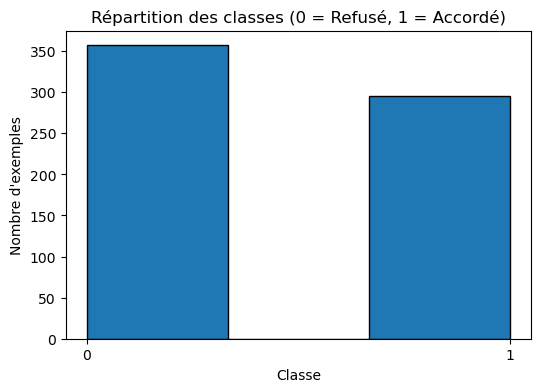


1. RÉSULTATS SUR DONNÉES BRUTES (Numériques)
Modèle          | Métriques                     
---------------------------------------------
KNN             | Accuracy: 0.688 | AUC: 0.727
CART            | Accuracy: 0.749 | AUC: 0.746
RandomForest    | Accuracy: 0.798 | AUC: 0.866
MLP             | Accuracy: 0.719 | AUC: 0.727
AdaBoost        | Accuracy: 0.817 | AUC: 0.872

2. RÉSULTATS SUR DONNÉES NORMALISÉES
Modèle          | Métriques                     
---------------------------------------------
KNN             | Accuracy: 0.758 | AUC: 0.821
CART            | Accuracy: 0.749 | AUC: 0.746
RandomForest    | Accuracy: 0.798 | AUC: 0.867
MLP             | Accuracy: 0.798 | AUC: 0.860
AdaBoost        | Accuracy: 0.817 | AUC: 0.872


In [24]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler

# --- 1. Analyse de la répartition des classes ---
plt.figure(figsize=(6, 4))
plt.hist(y, bins=3, edgecolor='black')
plt.title("Répartition des classes (0 = Refusé, 1 = Accordé)")
plt.xticks([0, 1])
plt.xlabel("Classe")
plt.ylabel("Nombre d'exemples")
plt.show()

# --- 2. Redéfinition de la fonction d'évaluation (Sécurité) ---
def evaluation(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    try:
        y_proba = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_proba)
    except:
        auc = 0.5 # Cas où le modèle ne gère pas les probas
    
    acc = accuracy_score(y_test, y_pred)
    print(f"{model_name:<15} | Accuracy: {acc:.3f} | AUC: {auc:.3f}")
    return acc

def run_classifiers(X_train, X_test, y_train, y_test):
    clfs = {
        'KNN': KNeighborsClassifier(n_neighbors=5),
        'CART': DecisionTreeClassifier(random_state=1),
        'RandomForest': RandomForestClassifier(n_estimators=100, random_state=1),
        'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), max_iter=1000, random_state=1),
        'AdaBoost': AdaBoostClassifier(random_state=1)
    }
    
    print(f"{'Modèle':<15} | {'Métriques':<30}")
    print("-" * 45)
    
    scores = {}
    for name, model in clfs.items():
        model.fit(X_train, y_train)
        scores[name] = evaluation(model, X_test, y_test, name)

# --- 3. Exécution sur Données BRUTES (Numériques) ---
print("\n" + "="*40)
print("1. RÉSULTATS SUR DONNÉES BRUTES (Numériques)")
print("="*40)
run_classifiers(X_train, X_test, y_train, y_test)

# --- 4. Normalisation et Exécution ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n" + "="*40)
print("2. RÉSULTATS SUR DONNÉES NORMALISÉES")
print("="*40)
run_classifiers(X_train_scaled, X_test_scaled, y_train, y_test)

In [25]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("\n=== TRAITEMENT COMPLET (HÉTÉROGÈNE & MANQUANTS) ===")

# 1. Rechargement propre des données
# On utilise header=None car pas de titres, et on gère les séparateurs
try:
    df = pd.read_csv("credit.data", sep='\t', header=None, na_values='?')
except:
    df = pd.read_csv("credit.data", sep=',', header=None, na_values='?')

# 2. Séparation X et y
X = df.iloc[:, :-1] # Toutes les colonnes sauf la dernière
y = df.iloc[:, -1]  # La dernière colonne

# Binarisation de la cible
y = np.where(y == '+', 1, 0)

# 3. Identification des colonnes (Index)
# Numériques : 1, 2, 7, 10, 13, 14
col_num = [1, 2, 7, 10, 13, 14]
# Catégorielles : Le reste (0, 3, 4, 5, 6, 8, 9, 11, 12)
col_cat = [0, 3, 4, 5, 6, 8, 9, 11, 12]

print(f"Nombre de variables numériques : {len(col_num)}")
print(f"Nombre de variables catégorielles : {len(col_cat)}")

# 4. Création des Pipelines de transformation
# Pour les chiffres : On remplace les NaN par la moyenne + Normalisation
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Pour le texte : On remplace les NaN par le plus fréquent + OneHotEncoder
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# On combine les deux avec un ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, col_num),
        ('cat', categorical_transformer, col_cat)
    ])

# 5. Application du pré-traitement
# Cela va créer une grosse matrice avec tout nettoyé et encodé
X_processed = preprocessor.fit_transform(X)

print(f"Taille des données après traitement : {X_processed.shape}")
# Note : Le nombre de colonnes va augmenter car OneHotEncoder crée une colonne par catégorie

# 6. Split Train / Test
X_train_final, X_test_final, y_train, y_test = train_test_split(X_processed, y, test_size=0.5, random_state=1)

# 7. Lancement des classifieurs sur ce jeu de données "Ultime"
print("\n" + "*"*50)
print("RÉSULTATS SUR DONNÉES COMPLÈTES (Num + Cat + Imputation)")
print("*"*50)

# On réutilise ta fonction run_classifiers
run_classifiers(X_train_final, X_test_final, y_train, y_test)


=== TRAITEMENT COMPLET (HÉTÉROGÈNE & MANQUANTS) ===
Nombre de variables numériques : 6
Nombre de variables catégorielles : 9
Taille des données après traitement : (688, 46)

**************************************************
RÉSULTATS SUR DONNÉES COMPLÈTES (Num + Cat + Imputation)
**************************************************
Modèle          | Métriques                     
---------------------------------------------
KNN             | Accuracy: 0.852 | AUC: 0.909
CART            | Accuracy: 0.826 | AUC: 0.826
RandomForest    | Accuracy: 0.884 | AUC: 0.932
MLP             | Accuracy: 0.860 | AUC: 0.920
AdaBoost        | Accuracy: 0.860 | AUC: 0.930


In [1]:
import pandas as pd
import numpy as np
import time
import warnings

# Bibliothèques Scikit-learn
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer 
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import make_scorer, accuracy_score, precision_score, roc_auc_score
from sklearn.pipeline import Pipeline

# Modèles
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

# --- DÉFINITION DES CLASSIFIEURS ---
clfs = {
    'CART': DecisionTreeClassifier(criterion='gini', random_state=1),
    'ID3': DecisionTreeClassifier(criterion='entropy', random_state=1),
    'Decision Stump': DecisionTreeClassifier(max_depth=1, random_state=1),
    'MLP (20,10)': MLPClassifier(hidden_layer_sizes=(20, 10), max_iter=200, random_state=1),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Bagging': BaggingClassifier(n_estimators=50, random_state=1),
    'AdaBoost': AdaBoostClassifier(n_estimators=50, random_state=1),
    'Random Forest': RandomForestClassifier(n_estimators=50, random_state=1),
    'XGBoost': XGBClassifier(n_estimators=50, use_label_encoder=False, eval_metric='logloss', random_state=1)
}

# --- FONCTION DE COMPARAISON ---
def custom_metric(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    return (acc + prec) / 2

def run_classifiers_cv(clfs, X, Y, n_splits=10):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=0)
    custom_scorer = make_scorer(custom_metric)
    
    print(f"{'Classifier':<20} | {'Acc':<8} | {'AUC':<8} | {'(Acc+P)/2':<10} | {'Time'}")
    print("-" * 75)

    for name, clf in clfs.items():
        start_time = time.time()
        
        # Accuracy
        cv_acc = cross_val_score(clf, X, Y, cv=kf, scoring='accuracy')
        
        # AUC (Aire sous la courbe ROC) - Ajout demandé
        try:
            cv_auc = cross_val_score(clf, X, Y, cv=kf, scoring='roc_auc')
        except:
            cv_auc = np.array([0.0])
            
        # Métrique (Acc+Prec)/2
        cv_custom = cross_val_score(clf, X, Y, cv=kf, scoring=custom_scorer)
        
        t = time.time() - start_time
        
        print(f"{name:<20} | {np.mean(cv_acc):.3f}    | {np.mean(cv_auc):.3f}    | {np.mean(cv_custom):.3f}      | {t:.2f}s")

# II. Apprentissage supervisé : Données hétérogènes

## 1. Données numériques uniquement (sans valeurs manquantes)

Dans cette première étape, nous chargeons le fichier `credit.data`. Nous transformons le DataFrame en tableau Numpy et nous ne conservons que les variables caractéristiques numériques (indices 1, 2, 7, 10, 13, 14).

Nous remplaçons les valeurs manquantes `'?'` par `nan`, convertissons le tout en flottants, puis supprimons toutes les lignes contenant au moins une valeur `nan` pour obtenir un jeu de données propre. Enfin, nous comparons les algorithmes sur ces données brutes puis normalisées.

In [6]:
print("--- 1. CHARGEMENT ET PRÉPARATION (Numérique uniquement) ---")

# CORRECTION ICI : on utilise sep='\t' (tabulation)
df = pd.read_csv('credit.data', header=None, sep='\t')

# Transformation en Numpy Array
data = df.values

# Séparation Features / Target
X_raw = data[:, :-1]
Y_raw = data[:, -1]

# Indices des colonnes numériques
col_num = [1, 2, 7, 10, 13, 14]

# Création du sous-ensemble numérique
X_num = X_raw[:, col_num]

# Remplacement des '?' par des NaN
X_num[X_num == '?'] = np.nan

# Conversion en type float
X_num = X_num.astype(float)

# Suppression des individus contenant des nan
rows_to_keep = ~np.isnan(X_num).any(axis=1)
X_num_clean = X_num[rows_to_keep]
Y_clean = Y_raw[rows_to_keep]

# Binarisation de la target (+ en 1 et - en 0)
Y_clean = np.where(Y_clean == '+', 1, 0)

# Analyse des propriétés
print(f"Taille de l'échantillon (shape) : {X_num_clean.shape}")
print(f"Nombre d'exemples positifs : {np.sum(Y_clean == 1)}")
print(f"Nombre d'exemples négatifs : {np.sum(Y_clean == 0)}")

# Exécution sur données brutes
print("\n>>> Comparaison sur données BRUTES <<<")
run_classifiers_cv(clfs, X_num_clean, Y_clean)

# Normalisation et nouvelle exécution
print("\n>>> Comparaison sur données NORMALISÉES (StandardScaler) <<<")
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num_clean)
run_classifiers_cv(clfs, X_num_scaled, Y_clean)

--- 1. CHARGEMENT ET PRÉPARATION (Numérique uniquement) ---
Taille de l'échantillon (shape) : (666, 6)
Nombre d'exemples positifs : 299
Nombre d'exemples négatifs : 367

>>> Comparaison sur données BRUTES <<<
Classifier           | Acc      | AUC      | (Acc+P)/2  | Time
---------------------------------------------------------------------------
CART                 | 0.716    | 0.711    | 0.698      | 0.59s
ID3                  | 0.739    | 0.734    | 0.722      | 0.57s
Decision Stump       | 0.743    | 0.723    | 0.804      | 0.17s
MLP (20,10)          | 0.694    | 0.724    | 0.698      | 4.62s
KNN (k=5)            | 0.709    | 0.733    | 0.710      | 0.22s
Bagging              | 0.787    | 0.834    | 0.786      | 10.62s
AdaBoost             | 0.790    | 0.853    | 0.800      | 5.18s
Random Forest        | 0.788    | 0.841    | 0.798      | 4.58s
XGBoost              | 0.787    | 0.844    | 0.781      | 2.44s

>>> Comparaison sur données NORMALISÉES (StandardScaler) <<<
Classifier   

## 2. Base originale complète (Traitement des données manquantes)

Nous reprenons la totalité de la base (15 variables). Cette fois, nous n'effaçons pas les lignes incomplètes. Nous appliquons une stratégie d'**imputation** :
* `mean` (moyenne) pour les variables numériques.
* `most_frequent` (valeur la plus fréquente) pour les variables catégorielles.

Ensuite, nous encodons les variables catégorielles à l'aide de `OneHotEncoder` pour transformer les modalités en variables binaires. Finalement, nous concaténons les données numériques normalisées et les données catégorielles encodées pour lancer la comparaison finale.

In [7]:
print("--- 2. TRAITEMENT COMPLET (Imputation & Encodage) ---")

# On recharge proprement avec le bon séparateur
df = pd.read_csv('credit.data', header=None, sep='\t')
data = df.values

X = data[:, :-1]
Y = np.where(data[:, -1] == '+', 1, 0) 

# Indices des colonnes
col_num = [1, 2, 7, 10, 13, 14]
col_cat = [0, 3, 4, 5, 6, 8, 9, 11, 12]

# --- A. Variables Numériques ---
X_num = np.copy(X[:, col_num])
X_num[X_num == '?'] = np.nan
X_num = X_num.astype(float)

imp_num = SimpleImputer(missing_values=np.nan, strategy='mean')
X_num = imp_num.fit_transform(X_num)

scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

# --- B. Variables Catégorielles ---
X_cat = np.copy(X[:, col_cat])
X_cat[X_cat == '?'] = np.nan # Uniformisation

imp_cat = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
X_cat = imp_cat.fit_transform(X_cat)

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_cat_bin = encoder.fit_transform(X_cat)

# --- C. Construction Finale ---
X_final = np.concatenate((X_num_scaled, X_cat_bin), axis=1)

print(f"Dimension du jeu de données final : {X_final.shape}")

print("\n>>> Comparaison sur le JEU DE DONNÉES COMPLET <<<")
run_classifiers_cv(clfs, X_final, Y)

--- 2. TRAITEMENT COMPLET (Imputation & Encodage) ---
Dimension du jeu de données final : (688, 46)

>>> Comparaison sur le JEU DE DONNÉES COMPLET <<<
Classifier           | Acc      | AUC      | (Acc+P)/2  | Time
---------------------------------------------------------------------------
CART                 | 0.815    | 0.814    | 0.804      | 0.46s
ID3                  | 0.820    | 0.819    | 0.803      | 0.53s
Decision Stump       | 0.856    | 0.866    | 0.823      | 0.19s
MLP (20,10)          | 0.855    | 0.920    | 0.843      | 17.86s
KNN (k=5)            | 0.840    | 0.900    | 0.841      | 0.19s
Bagging              | 0.875    | 0.930    | 0.862      | 9.13s
AdaBoost             | 0.856    | 0.936    | 0.844      | 5.32s
Random Forest        | 0.878    | 0.930    | 0.869      | 4.59s
XGBoost              | 0.866    | 0.925    | 0.856      | 4.00s
